# Bank Account Prediction - Financial Inclusion in Africa

In [78]:
#Phase 1
#Loading of  Libraries


In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb



In [80]:
import os

base = "/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank"
for root, _, files in os.walk(base):
    for f in files:
        if f.endswith(".csv"):
            print(os.path.join(root, f))

/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/rawdata.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-log2.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-arcsinh.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-arctanh.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-sin.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-cos.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/umath-validation-set-cbrt.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJE

/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/sample_data/msft.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/sample_data/data_x_x2_x3.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/sample_data/Stocks.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.venv/lib/python3.12/site-packages/scipy/signal/tests/data/GLB.Ts+dSST.csv
/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.ipynb_checkpoints/rawdata-checkpoint.csv


In [81]:
import pandas as pd

df = pd.read_csv("/Users/aguuchechukwueric/Desktop/ML MID TERM PROJECT/bank/.ipynb_checkpoints/rawdata-checkpoint.csv")
df.head(10)

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed
5,Kenya,2018,uniqueid_6,No,Rural,No,7,26,Female,Spouse,Married/Living together,Primary education,Informally employed
6,Kenya,2018,uniqueid_7,No,Rural,Yes,7,32,Female,Spouse,Married/Living together,Primary education,Self employed
7,Kenya,2018,uniqueid_8,No,Rural,Yes,1,42,Female,Head of Household,Married/Living together,Tertiary education,Formally employed Government
8,Kenya,2018,uniqueid_9,Yes,Rural,Yes,3,54,Male,Head of Household,Married/Living together,Secondary education,Farming and Fishing
9,Kenya,2018,uniqueid_10,No,Urban,Yes,3,76,Female,Head of Household,Divorced/Seperated,No formal education,Remittance Dependent


In [82]:
# inspect data

In [83]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


,year,household_size,age_of_respondent
count,23524.000000,23524.000000,23524.000000
mean,2016.975939,3.797483,38.805220
std,0.847371,2.227613,16.520569
min,2016.000000,1.000000,16.000000
25%,2016.000000,2.000000,26.000000
50%,2017.000000,3.000000,35.000000
75%,2018.000000,5.000000,49.000000
max,2018.000000,21.000000,100.000000


In [84]:
df.shape

(23524, 13)

In [85]:
df.nunique()

country                      4
year                         3
uniqueid                  8735
bank_account                 2
location_type                2
cellphone_access             2
household_size              20
age_of_respondent           85
gender_of_respondent         2
relationship_with_head       6
marital_status               5
education_level              6
job_type                    10
dtype: int64

In [86]:
df.isnull().sum()

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64

bank_account
No     20212
Yes     3312
Name: count, dtype: int64


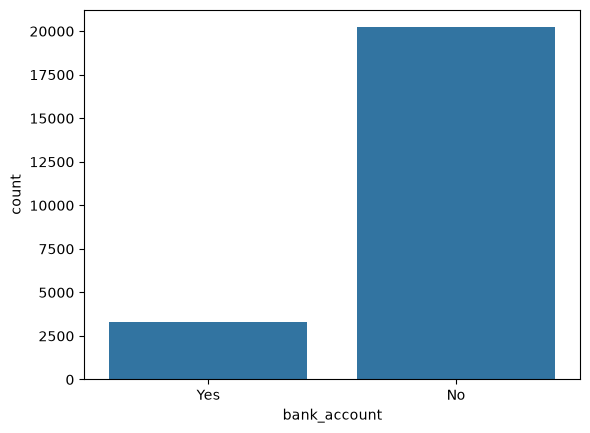

In [87]:
# Target Analysis
print(df["bank_account"].value_counts())
df["bank_account"].value_counts(normalize=True)
sns.countplot(data =df,  x= "bank_account")
plt.show()

In [88]:
#Categorical features and cardinality

In [89]:
cat_cols = [
    "country", "location_type", "cellphone_access", 
    "gender_of_respondent", "relationship_with_head", 
    "marital_status", "education_level", "job_type"
]

for col in cat_cols:
    print(f"--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts())
    print()  # Adds a blank line for readability

--- country (4 unique) ---
country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101
Name: count, dtype: int64

--- location_type (2 unique) ---
location_type
Rural    14343
Urban     9181
Name: count, dtype: int64

--- cellphone_access (2 unique) ---
cellphone_access
Yes    17454
No      6070
Name: count, dtype: int64

--- gender_of_respondent (2 unique) ---
gender_of_respondent
Female    13877
Male       9647
Name: count, dtype: int64

--- relationship_with_head (6 unique) ---
relationship_with_head
Head of Household      12831
Spouse                  6520
Child                   2229
Parent                  1086
Other relative           668
Other non-relatives      190
Name: count, dtype: int64

--- marital_status (5 unique) ---
marital_status
Married/Living together    10749
Single/Never Married        7983
Widowed                     2708
Divorced/Seperated          2076
Dont know                      8
Name: count, dtype: int64

--- education_level (6 unique) --

In [90]:
#  Numeric features and outliers

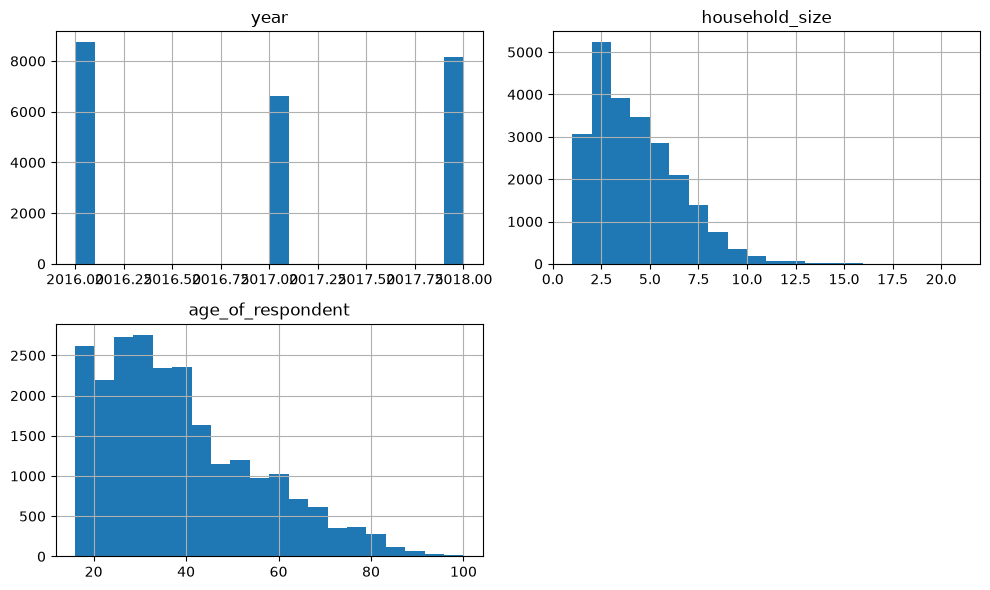

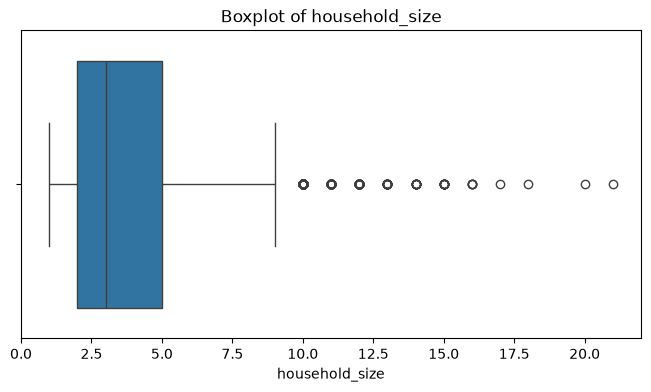

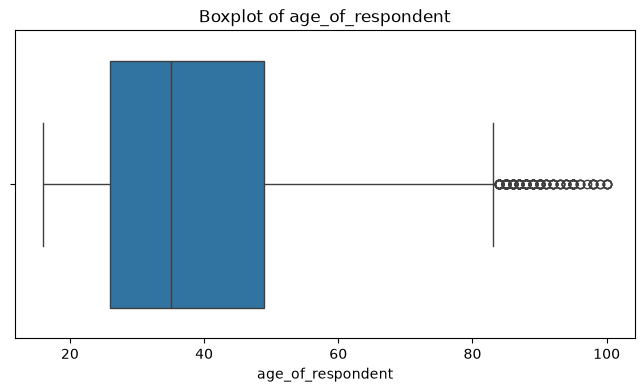

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

num_col = ["year", "household_size", "age_of_respondent"]
df[num_col].hist(figsize=(10, 6), bins=20)
plt.tight_layout()
plt.show()

for c in ["household_size", "age_of_respondent"]:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[c])
    plt.title(f"Boxplot of {c}")
    plt.show()

In [92]:
#- Features vs target
from IPython.display import display

for c in cat_cols:
    print(f"--- Feature: {c.upper()} ---")
    # Multiplying by 100 makes the proportions easier to read as percentages
    ct = pd.crosstab(df[c], df['bank_account'], normalize='index').round(3) * 100
    display(ct)
    print("\n" + "="*40 + "\n")

--- Feature: COUNTRY ---


bank_account,No,Yes
country,,
Kenya,74.9,25.1
Rwanda,88.5,11.5
Tanzania,90.8,9.2
Uganda,91.4,8.6




--- Feature: LOCATION_TYPE ---


bank_account,No,Yes
location_type,,
Rural,88.3,11.7
Urban,82.1,17.9




--- Feature: CELLPHONE_ACCESS ---


bank_account,No,Yes
cellphone_access,,
No,98.3,1.7
Yes,81.6,18.4


... (6 outputs left out)



--- Feature: EDUCATION_LEVEL ---


bank_account,No,Yes
education_level,,
No formal education,96.1,3.9
Other/Dont know/RTA,68.6,31.4
Primary education,91.5,8.5
Secondary education,76.7,23.3
Tertiary education,48.9,51.1
Vocational/Specialised training,43.0,57.0




--- Feature: JOB_TYPE ---


bank_account,No,Yes
job_type,,
Dont Know/Refuse to answer,88.9,11.1
Farming and Fishing,88.3,11.7
Formally employed Government,22.5,77.5
Formally employed Private,45.9,54.1
Government Dependent,79.8,20.2
Informally employed,92.0,8.0
No Income,97.9,2.1
Other Income,81.9,18.1
Remittance Dependent,90.5,9.5


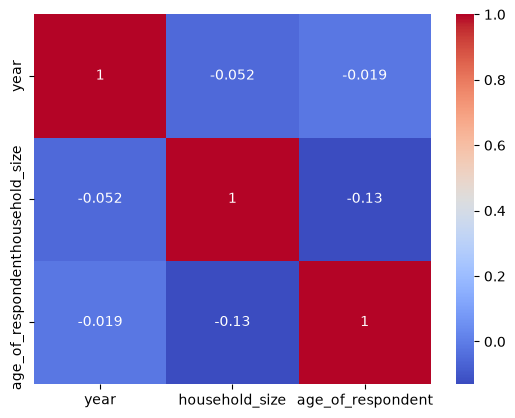

In [93]:
# Correlation (numeric)
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm')
plt.show()

In [94]:
# Phase 2 - Preprocessing and modeling

In [95]:
from sklearn.model_selection import train_test_split
y = (df['bank_account'] == 'Yes').astype(int)
X = df.drop(columns=['bank_account', 'uniqueid'])
X_train, X_val, y_train, y_val = train_test_split(
 X, y, test_size=0.2, stratify=y, random_state=42)

In [96]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
num_cols = ['household_size', 'age_of_respondent']
cat_cols = ['country', 'year', 'location_type', 'cellphone_access',
 'gender_of_respondent', 'relationship_with_head',
 'marital_status', 'education_level', 'job_type']
pre = ColumnTransformer([
 ('num', StandardScaler(), num_cols),
 ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
pre.fit(X_train)
X_train_prepared = pre.transform(X_train)
X_val_prepared = pre.transform(X_val)
print(X_train_prepared.shape[1] == X_val_prepared.shape[1])

True


#Baseline: logistic regression

In [98]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score,
 classification_report, confusion_matrix)
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_prepared, y_train)
pred = lr.predict(X_val_prepared)
proba = lr.predict_proba(X_val_prepared)[:, 1]
print('accuracy', accuracy_score(y_val, pred))
print('auc', roc_auc_score(y_val, proba))
print(classification_report(y_val, pred))
print(confusion_matrix(y_val, pred))

accuracy 0.8890541976620616
auc 0.8641968551066966
              precision    recall  f1-score   support

           0       0.90      0.98      0.94      4043
           1       0.71      0.36      0.48       662

    accuracy                           0.89      4705
   macro avg       0.81      0.67      0.71      4705
weighted avg       0.88      0.89      0.87      4705

[[3944   99]
 [ 423  239]]


Tree models

In [99]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
models = {
 'random_forest': RandomForestClassifier(n_estimators=200, random_state=42),
 'xgboost': XGBClassifier(eval_metric='logloss', random_state=42),
}
for name, m in models.items():
 m.fit(X_train_prepared, y_train)
 p = m.predict(X_val_prepared)
 pr = m.predict_proba(X_val_prepared)[:, 1]
 print(name, 'acc', accuracy_score(y_val, p), 'auc', roc_auc_score(y_val, pr))

random_forest acc 0.8641870350690755 auc 0.8288448274702538
xgboost acc 0.8882040382571732 auc 0.8634854692717934


 Hyperparameter tuning

In [103]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
pipe = Pipeline([('pre', pre),
 ('clf', XGBClassifier(eval_metric='logloss', random_state=42))])
param_grid = {
 'clf__max_depth': [3, 5],
 'clf__n_estimators': [100, 200],
 'clf__learning_rate': [0.05, 0.1],
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_)
best = grid.best_estimator_
print('val auc', roc_auc_score(y_val, best.predict_proba(X_val)[:, 1]))

{'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200}
val auc 0.8769937671541503


 Feature importance and save model

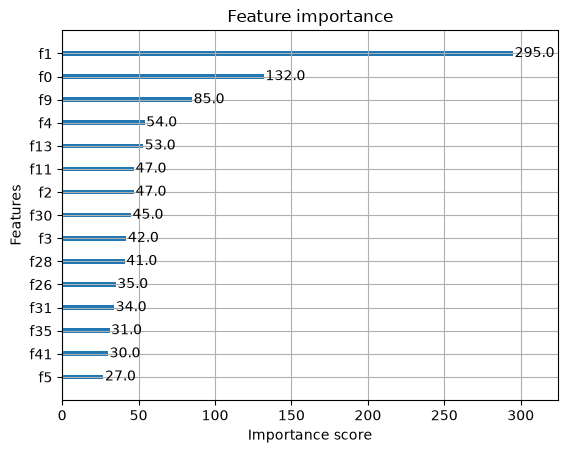

['model.bin']

In [104]:
import joblib
from xgboost import plot_importance
plot_importance(best.named_steps['clf'], max_num_features=15)
plt.show()
joblib.dump(best, 'model.bin')